# Step 8b — TabPFN and TabICL on the paper1 bundle, 10-fold

**Standalone:** the Run part needs only this notebook and the bundle from `step8_export_bundle.ipynb`, so it can run on any GPU machine. Packages: python ≥ 3.10, numpy, pandas, scikit-learn, torch, `tabpfn==9.2.0`, `tabicl==2.2.0` (see `modeling/requirements-foundation.txt`).

**Variants** (fixed before running; package defaults, no tuning, since these models are meant to be used without tuning):

| variant | model | target | score |
|---|---|---|---|
| tabpfn_clf | TabPFNClassifier (default checkpoint, TabPFN-3.5) | 0/1 label | P(depressed) |
| tabpfn_reg | TabPFNRegressor | PHQ-9 total | predicted total |
| tabicl_clf | TabICLClassifier (default checkpoint, TabICLv2) | 0/1 label | P(depressed) |
| tabicl_reg | TabICLRegressor | PHQ-9 total | predicted total |

For each test fold the model is fitted on the other 9 folds only. Categorical features are passed as pandas `category` columns; continuous features as floats (−1 = not applicable, NaN = missing).

TabPFN-3.5 weights need a (free, non-commercial) license: accept it once at https://ux.priorlabs.ai and set `TABPFN_TOKEN` on a headless machine. TabICL weights download from Hugging Face on first use.

Each (model, fold) is written to `OUT_DIR/<model>/fold<k>.csv` (SEQN, fold, depression, phq9, score) as soon as it finishes; finished ones are skipped on a rerun, so the run can be stopped and resumed. `QUICK`: fold 0 only, 2,000 training rows (checks the setup in a few minutes; written to `OUT_DIR/quick/`).

The Results part reads `OUT_DIR` and, when they are there, steps 6 and 7's predictions on the same folds, to compare fold by fold.

In [1]:
import json
import os
import platform
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

RUN = False      # True: fit the models (GPU machine)
QUICK = False    # with RUN: fold 0, 2,000 training rows
MODELS = ["tabpfn_clf", "tabpfn_reg", "tabicl_clf", "tabicl_reg"]
FOLDS = list(range(10))
DEVICE = None    # None: cuda if available, else cpu
SEED = 42
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
QUICK = QUICK or os.environ.get("NHANES_QUICK") == "1"

# Inside this repository the bundle and outputs default to $NHANES_WORK/modeling; standalone, set BUNDLE / OUT_DIR.
try:
    import sys
    _cwd = Path.cwd().resolve()
    sys.path.insert(0, str(next(p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file())))
    from nhanes.paths import RESULTS
except StopIteration:
    RESULTS = None
BUNDLE = Path(os.environ.get("STEP8_BUNDLE", RESULTS / "step8_bundle" if RESULTS else "step8_bundle"))
OUT_DIR = Path(os.environ.get("STEP8_OUT", RESULTS / "step8_out" if RESULTS else "step8_out"))

## Run

In [2]:
if RUN:
    import torch
    from sklearn.metrics import roc_auc_score

    def load(bundle):
        data = pd.read_csv(bundle / "data.csv.gz")
        cols = json.loads((bundle / "columns.json").read_text())
        X = data[cols["categorical"] + cols["continuous"]].copy()
        for c in cols["categorical"]:
            X[c] = X[c].astype("Int64").astype("category")
        X[cols["continuous"]] = X[cols["continuous"]].astype(float)
        return data, X

    def make(model, device):
        if model.startswith("tabpfn"):
            from tabpfn import TabPFNClassifier, TabPFNRegressor
            cls = TabPFNClassifier if model.endswith("clf") else TabPFNRegressor
            return cls(device=device, random_state=SEED)
        from tabicl import TabICLClassifier, TabICLRegressor
        cls = TabICLClassifier if model.endswith("clf") else TabICLRegressor
        return cls(device=device, random_state=SEED)

    def score(m, model, X, chunk):
        """Predict in chunks of `chunk` rows (0 = all at once)."""
        parts = [X] if not chunk else [X.iloc[i:i + chunk] for i in range(0, len(X), chunk)]
        if model.endswith("clf"):
            return np.concatenate([m.predict_proba(p)[:, list(m.classes_).index(1)] for p in parts])
        return np.concatenate([np.asarray(m.predict(p), dtype=float) for p in parts])

    def run_one(model, data, X, k, device, quick):
        tr, te = np.flatnonzero(data.fold != k), np.flatnonzero(data.fold == k)
        if quick:
            tr = np.random.default_rng(SEED).choice(tr, 2000, replace=False)
        y = data.depression if model.endswith("clf") else data.phq9.astype(float)
        m = make(model, device).fit(X.iloc[tr], y.iloc[tr])
        for chunk in (0, 1000, 250):
            try:
                return score(m, model, X.iloc[te], chunk), te
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache()
                print(f"  out of GPU memory predicting fold {k} with chunk={chunk or 'all'}; retrying smaller", flush=True)
        raise RuntimeError("out of GPU memory even with 250-row chunks")

    device = DEVICE or ("cuda" if torch.cuda.is_available() else "cpu")
    data, X = load(BUNDLE)
    out = OUT_DIR / "quick" if QUICK else OUT_DIR
    folds = [0] if QUICK else FOLDS
    gpu = torch.cuda.get_device_name(device) if str(device).startswith("cuda") else "cpu"
    print(f"{len(data)} people, {X.shape[1]} features; device {device} ({gpu}); "
          f"torch {torch.__version__}, python {platform.python_version()}", flush=True)
    for model in MODELS:
        (out / model).mkdir(parents=True, exist_ok=True)
        for k in folds:
            path = out / model / f"fold{k}.csv"
            if path.exists():
                print(f"{model} fold {k}: done before, skipped", flush=True)
                continue
            t0 = time.time()
            s, te = run_one(model, data, X, k, device, QUICK)
            res = data.iloc[te][["SEQN", "fold", "depression", "phq9"]].assign(score=s)
            res.to_csv(path, index=False)
            print(f"{model} fold {k}: AUROC {roc_auc_score(res.depression, res.score):.3f}  "
                  f"{(time.time() - t0) / 60:.1f} min", flush=True)

## Results: AUROC per fold

In [3]:
from sklearn.metrics import roc_auc_score  # noqa: E402

preds = {m: pd.concat([pd.read_csv(p) for p in sorted((OUT_DIR / m).glob("fold*.csv"))], ignore_index=True)
         for m in MODELS if (OUT_DIR / m).is_dir()}
per_fold = pd.DataFrame({m: p.groupby("fold").apply(lambda g: roc_auc_score(g.depression, g.score)) for m, p in preds.items()})
display(per_fold.agg(["mean", "std", "min"]).round(3))
print("people with a prediction:", {m: len(p) for m, p in preds.items()})

,tabpfn_clf,tabpfn_reg,tabicl_clf,tabicl_reg
mean,0.797,0.799,0.791,0.791
std,0.011,0.012,0.011,0.012
min,0.774,0.771,0.768,0.762


people with a prediction: {'tabpfn_clf': 36259, 'tabpfn_reg': 36259, 'tabicl_clf': 36259, 'tabicl_reg': 36259}


## Compared with steps 6 and 7 on the same folds

Fold-by-fold differences (mean over the 10 folds and how many folds are higher). The bootstrap CIs in `modeling/README.md` come from resampling people within each fold.

,model,vs,mean difference,folds higher
0,tabpfn_reg,"elastic net, raw table (≈ paper1's method)",0.0124,10
1,tabpfn_reg,"step 6 ensemble, recoded",0.0080,10
2,tabpfn_reg,step 7 Poisson XGBoost,0.0057,10
3,tabpfn_clf,"elastic net, raw table (≈ paper1's method)",0.0111,10
4,tabpfn_clf,"step 6 ensemble, recoded",0.0067,10
5,tabpfn_clf,step 7 Poisson XGBoost,0.0044,10


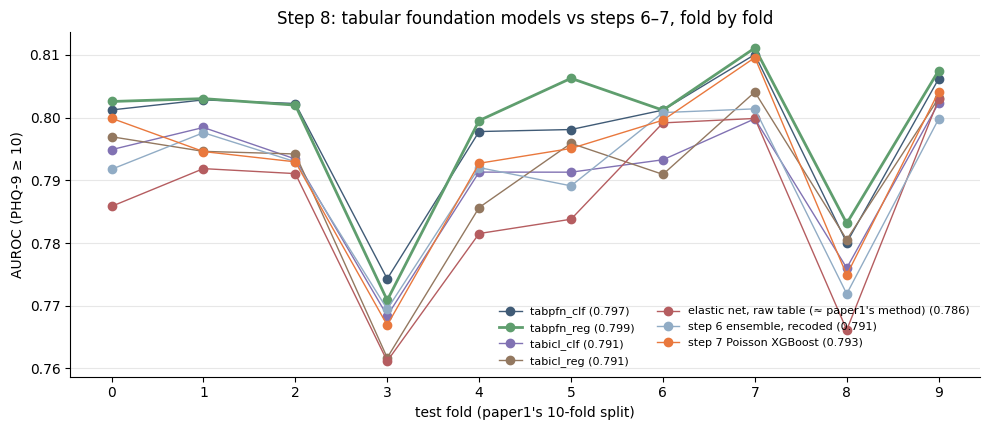

In [4]:
comparison = None
if RESULTS is not None and (RESULTS / "step6_paper1_recoded" / "kfold10_raw" / "metrics.csv").exists():
    s6 = {t: pd.read_csv(RESULTS / "step6_paper1_recoded" / f"kfold10_{t}" / "metrics.csv") for t in ["raw", "recoded"]}
    s7 = pd.read_csv(RESULTS / "step7_phq9_target" / "metrics.csv")
    ref = {"elastic net, raw table (≈ paper1's method)": s6["raw"][s6["raw"].model == "logreg"],
           "step 6 ensemble, recoded": s6["recoded"][s6["recoded"].model == "ensemble"],
           "step 7 Poisson XGBoost": s7[s7.model == "poisson+xgboost"]}
    ref = {k: v.assign(fold=v.split.str[4:].astype(int)).set_index("fold").auroc for k, v in ref.items()}
    rows = []
    for m in [c for c in ["tabpfn_reg", "tabpfn_clf"] if c in per_fold]:
        for name, r in ref.items():
            d = per_fold[m] - r.reindex(per_fold.index)
            rows.append({"model": m, "vs": name, "mean difference": round(d.mean(), 4), "folds higher": int((d > 0).sum())})
    comparison = pd.DataFrame(rows)
    display(comparison)

    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(10, 4.4))
    lines = {**{m: per_fold[m] for m in per_fold}, **ref}
    colors = ["#405B76", "#5F9E6E", "#8172B3", "#937860", "#B55D60", "#91ACC5", "#E9783D"]
    for (name, s), c in zip(lines.items(), colors):
        ax.plot(s.index, s.values, "o-", color=c, label=f"{name} ({s.mean():.3f})", lw=2 if name == "tabpfn_reg" else 1)
    ax.set_xticks(range(10))
    ax.set_xlabel("test fold (paper1's 10-fold split)")
    ax.set_ylabel("AUROC (PHQ-9 ≥ 10)")
    ax.set_title("Step 8: tabular foundation models vs steps 6–7, fold by fold")
    ax.legend(frameon=False, fontsize=8, ncol=2)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()
else:
    print("steps 6 / 7 results not found here; run this part on the machine that holds them")